# Lab 2: Additional Components — Task 2

**Author:** Harvey Luna
**Team:** Wolfgang Klein, Sydney Bailey, Harvey Luna, Nashita Khandaker

The team's Lab 2 modeling for both tasks is in the
[Wolfgang Klein tab](https://lone-wolfgang.github.io/brfss2015-diabetes-eda/#Lab2/WolfgangKlein).

This tab covers the additional components remaining for Lab 2, worked on the Task 2
outreach model:

1. **Statistical comparison of the models at 95% confidence** (§2)
2. **Feature importance** (§3)
3. **Deployment** (§4)

Section 1 rebuilds the models these components need. It uses the same rows, features,
split, seed and metrics as the Wolfgang Klein tab, so the numbers line up with the
Task 2 results reported there.

## 1. Setup

Same preparation as the Task 2 model in the Wolfgang Klein tab: undiagnosed respondents
only, the four "told by a doctor" diagnoses withheld, BMI capped at 70, centered squared
terms for age and income, and a 70/15/15 stratified split at `SEED = 0`. Three models are
tuned by 5-fold cross-validation on average precision, and each gets the threshold that
maximizes F2 on validation.

In [1]:
# ---- Imports ----
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             precision_score, recall_score, fbeta_score, confusion_matrix)
from xgboost import XGBClassifier

# ---- Settings shared with Task 1 ----
SEED = 0
N_FOLDS = 5
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

In [2]:
# ---- Read the file and build the two outcomes ----
raw = pd.read_csv("../data/diabetes_012_health_indicators_BRFSS2015.csv")
raw["Diabetes_binary"] = (raw["Diabetes_012"] > 0).astype(int)
raw["NoCheck"] = 1 - raw["CholCheck"]

print(f"{len(raw):,} respondents")
print(f"No cholesterol check in 5 years: {raw['NoCheck'].mean():.2%}")

253,680 respondents
No cholesterol check in 5 years: 3.73%


In [3]:
# ---- Feature lists ----
BASE = ["HighBP", "HighChol", "BMI", "Smoker", "Stroke", "HeartDiseaseorAttack", "PhysActivity",
        "Fruits", "Veggies", "HvyAlcoholConsump", "AnyHealthcare", "NoDocbcCost", "GenHlth",
        "MentHlth", "PhysHlth", "DiffWalk", "Sex", "Age", "Education", "Income"]
TOLD = ["HighBP", "HighChol", "HeartDiseaseorAttack", "Stroke"]

FEATURES = [c for c in BASE if c not in TOLD] + ["Age_sq", "Income_sq"]
print(len(FEATURES), "features:", ", ".join(FEATURES))

18 features: BMI, Smoker, PhysActivity, Fruits, Veggies, HvyAlcoholConsump, AnyHealthcare, NoDocbcCost, GenHlth, MentHlth, PhysHlth, DiffWalk, Sex, Age, Education, Income, Age_sq, Income_sq


In [4]:
# ---- Clean and engineer features ----
df = raw.copy()
df["BMI"] = df["BMI"].clip(upper=70)
for col in ["Age", "Income"]:
    df[f"{col}_sq"] = (df[col] - df[col].mean()) ** 2

# ---- Keep undiagnosed respondents only ----
t2 = df[df["Diabetes_binary"] == 0]
X = t2[FEATURES].astype(float)
y = t2["NoCheck"].astype(int)

In [5]:
# ---- 70 / 15 / 15 stratified split ----
X_train, X_rest, y_train, y_rest = train_test_split(X, y, train_size=0.70, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_rest, y_rest, test_size=0.5, stratify=y_rest, random_state=SEED)

# ---- Check the split sizes and balance ----
pd.DataFrame({
    "rows": [len(y_train), len(y_val), len(y_test)],
    "positives": [y_train.sum(), y_val.sum(), y_test.sum()],
    "positive %": [100 * y_train.mean(), 100 * y_val.mean(), 100 * y_test.mean()],
}, index=["train", "validation", "test"])

,rows,positives,positive %
train,149592,6417,4.2897
validation,32055,1375,4.2895
test,32056,1375,4.2894


In [6]:
# ---- Cross-validation setup ----
cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
pos_weight = (1 - y_train.mean()) / y_train.mean()
models, cv_results = {}, {}

def summarize(name, search):
    # Store the best model and its cross-validated scores
    i = search.best_index_
    models[name] = search.best_estimator_
    cv_results[name] = {"CV AP": search.cv_results_["mean_test_AP"][i],
                        "AP sd": search.cv_results_["std_test_AP"][i],
                        "CV AUC": search.cv_results_["mean_test_AUC"][i]}
    print(name, search.best_params_)

In [7]:
# ---- Grid search over penalty strength and class weighting ----
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
lr_grid = {"logisticregression__C": np.logspace(-4, 2, 7),
           "logisticregression__class_weight": [None, "balanced"]}

lr_search = GridSearchCV(lr, lr_grid, cv=cv, scoring={"AP": "average_precision", "AUC": "roc_auc"},
                         refit="AP", n_jobs=-1)
lr_search.fit(X_train, y_train)
summarize("Logistic regression", lr_search)

Logistic regression {'logisticregression__C': np.float64(10.0), 'logisticregression__class_weight': None}


In [8]:
# ---- Randomized search over tree size, sampling and class weighting ----
rf = RandomForestClassifier(random_state=SEED, n_jobs=1)
rf_grid = {"n_estimators": [200, 300],
           "max_depth": [8, 12, 16, None],
           "min_samples_leaf": [10, 20, 50, 100],
           "max_features": [3, 4, 6, 8],
           "max_samples": [0.2, 0.4],
           "class_weight": [None, "balanced_subsample"]}

rf_search = RandomizedSearchCV(rf, rf_grid, n_iter=10, cv=cv, random_state=SEED,
                               scoring={"AP": "average_precision", "AUC": "roc_auc"},
                               refit="AP", n_jobs=-1)
rf_search.fit(X_train, y_train)
summarize("Random forest", rf_search)

Random forest {'n_estimators': 200, 'min_samples_leaf': 20, 'max_samples': 0.4, 'max_features': 4, 'max_depth': 12, 'class_weight': None}


In [9]:
# ---- Randomized search over boosting, tree size and regularization ----
xgb = XGBClassifier(tree_method="hist", random_state=SEED, n_jobs=1, eval_metric="logloss")
xgb_grid = {"n_estimators": [200, 400, 800],
            "learning_rate": [0.02, 0.05, 0.1],
            "max_depth": [2, 3, 4, 6],
            "min_child_weight": [1, 10, 50, 200],
            "subsample": [0.6, 0.8, 1.0],
            "colsample_bytree": [0.5, 0.8, 1.0],
            "reg_lambda": [1, 5, 15],
            "scale_pos_weight": [1, pos_weight]}

xgb_search = RandomizedSearchCV(xgb, xgb_grid, n_iter=15, cv=cv, random_state=SEED,
                                scoring={"AP": "average_precision", "AUC": "roc_auc"},
                                refit="AP", n_jobs=-1)
xgb_search.fit(X_train, y_train)
summarize("XGBoost", xgb_search)

XGBoost {'subsample': 0.8, 'scale_pos_weight': 1, 'reg_lambda': 15, 'n_estimators': 800, 'min_child_weight': 200, 'max_depth': 4, 'learning_rate': 0.02, 'colsample_bytree': 1.0}


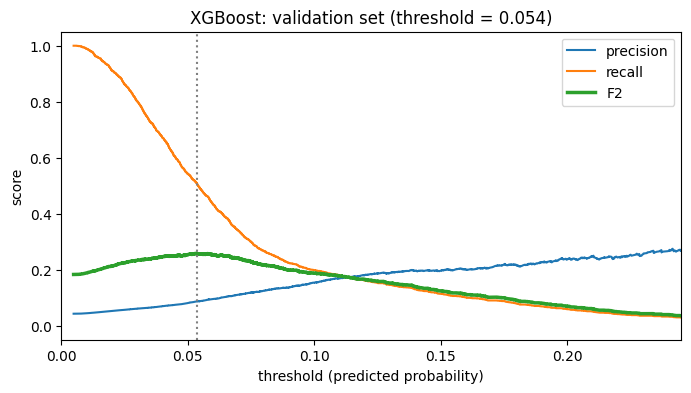

,threshold,validation F2
Logistic regression,0.0536,0.2525
Random forest,0.0527,0.2575
XGBoost,0.0535,0.2585


In [10]:
# ---- Find the F2-maximizing threshold on validation ----
def best_threshold(y_true, scores):
    prec, rec, thr = precision_recall_curve(y_true, scores)
    f2 = 5 * prec * rec / np.maximum(4 * prec + rec, 1e-12)
    i = np.argmax(f2[:-1])
    return thr[i], prec[:-1], rec[:-1], f2[:-1], thr

thresholds, val_f2 = {}, {}
for name, m in models.items():
    t, _, _, f2, _ = best_threshold(y_val, m.predict_proba(X_val)[:, 1])
    thresholds[name], val_f2[name] = t, f2.max()

# ---- Plot the curves for the best model ----
best = max(val_f2, key=val_f2.get)
t, prec, rec, f2, thr = best_threshold(y_val, models[best].predict_proba(X_val)[:, 1])

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(thr, prec, label="precision")
ax.plot(thr, rec, label="recall")
ax.plot(thr, f2, label="F2", lw=2.5)
ax.axvline(t, ls=":", color="gray")
ax.set_xlim(0, np.percentile(thr, 99.5))
ax.set(xlabel="threshold (predicted probability)", ylabel="score",
       title=f"{best}: validation set (threshold = {t:.3f})")
ax.legend()
plt.show()

pd.DataFrame({"threshold": thresholds, "validation F2": val_f2})

In [11]:
# ---- Score every model on the test set, once ----
rows = []
for name, m in models.items():
    s = m.predict_proba(X_test)[:, 1]
    pred = (s >= thresholds[name]).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append({"model": name, "F2": fbeta_score(y_test, pred, beta=2),
                 "recall": recall_score(y_test, pred), "precision": precision_score(y_test, pred),
                 "AP": average_precision_score(y_test, s), "AUC": roc_auc_score(y_test, s),
                 "TP": tp, "FP": fp, "FN": fn, "TN": tn})

results = pd.DataFrame(rows).set_index("model").sort_values("F2", ascending=False)
results

,F2,recall,precision,AP,AUC,TP,FP,FN,TN
model,,,,,,,,,
Random forest,0.2551,0.5142,0.0846,0.1113,0.7002,707,7648,668,23033
XGBoost,0.2516,0.4945,0.0848,0.1132,0.7018,680,7335,695,23346
Logistic regression,0.2503,0.4553,0.0893,0.1057,0.6942,626,6381,749,24300


## 2. Statistical comparison of the models at 95% confidence

Two tests. A **bootstrap** puts a 95% confidence interval around each model's test F2, which
shows how much of the ranking is sampling noise. **McNemar's test** then compares the two
best models directly on the rows where they disagree, which is the right test for two
classifiers scored on the same test set.

In [12]:
# ---- Bootstrap 95% confidence intervals for test F2 ----
rng = np.random.default_rng(SEED)
N_BOOT = 1000

preds = {n: (m.predict_proba(X_test)[:, 1] >= thresholds[n]).astype(int)
         for n, m in models.items()}
y_arr = y_test.to_numpy()

boot = {n: np.empty(N_BOOT) for n in models}
for b in range(N_BOOT):
    idx = rng.integers(0, len(y_arr), len(y_arr))        # resample test rows with replacement
    for n in models:
        boot[n][b] = fbeta_score(y_arr[idx], preds[n][idx], beta=2)

ci = pd.DataFrame({
    "test F2":  {n: fbeta_score(y_arr, preds[n], beta=2) for n in models},
    "CI lower": {n: np.percentile(boot[n], 2.5) for n in models},
    "CI upper": {n: np.percentile(boot[n], 97.5) for n in models},
}).sort_values("test F2", ascending=False)
ci["CI width"] = ci["CI upper"] - ci["CI lower"]
ci

,test F2,CI lower,CI upper,CI width
Random forest,0.2551,0.2398,0.2699,0.0301
XGBoost,0.2516,0.2365,0.2662,0.0297
Logistic regression,0.2503,0.2346,0.2661,0.0315


In [13]:
# ---- McNemar's test on the two best models ----
from scipy.stats import chi2

top2 = ci.index[:2].tolist()
a, b = preds[top2[0]], preds[top2[1]]
correct_a, correct_b = (a == y_arr), (b == y_arr)

n01 = int((~correct_a & correct_b).sum())     # only the second model is right
n10 = int((correct_a & ~correct_b).sum())     # only the first model is right

stat = (abs(n10 - n01) - 1) ** 2 / (n10 + n01)          # continuity-corrected
p = 1 - chi2.cdf(stat, df=1)

print(f"Comparing {top2[0]} with {top2[1]}")
print(f"  rows where only {top2[0]:<20} is correct : {n10:,}")
print(f"  rows where only {top2[1]:<20} is correct : {n01:,}")
print(f"  McNemar chi-square = {stat:.3f}, p = {p:.4f}")
print(f"  At the 95% level the difference is {'significant' if p < 0.05 else 'not significant'}.")

Comparing Random forest with XGBoost
  rows where only Random forest        is correct : 900
  rows where only XGBoost              is correct : 1,186
  McNemar chi-square = 38.938, p = 0.0000
  At the 95% level the difference is significant.


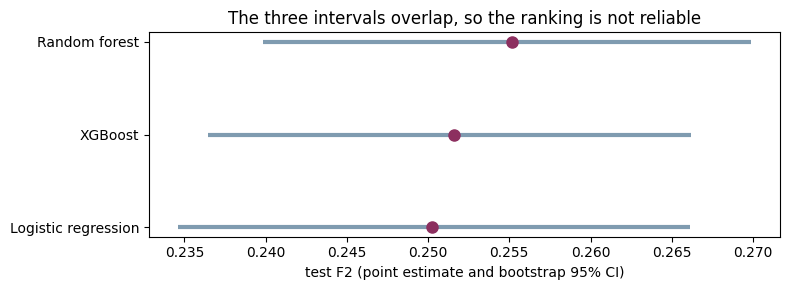

In [14]:
# ---- Plot the confidence intervals ----
fig, ax = plt.subplots(figsize=(8, 3))
yp = np.arange(len(ci))
ax.hlines(yp, ci["CI lower"], ci["CI upper"], color="#7f9bb0", lw=3)
ax.plot(ci["test F2"], yp, "o", color="#8c2f5f", ms=8)
ax.set_yticks(yp); ax.set_yticklabels(ci.index); ax.invert_yaxis()
ax.set_xlabel("test F2 (point estimate and bootstrap 95% CI)")
ax.set_title("The three intervals overlap, so the ranking is not reliable")
plt.tight_layout(); plt.show()

**The F2 ranking is not separable.** Random forest leads at 0.255, XGBoost is at 0.252 and
logistic regression at 0.250, but every interval is about 0.030 wide and all three overlap
almost completely. The spread between best and worst, 0.005, is a sixth of a single interval's
width. On F2 these three models cannot be ranked from this test set.

**McNemar finds a real difference, on a different question.** The two best models disagree on
2,086 test rows. XGBoost is correct on 1,186 of them and random forest on 900, giving a
chi-square of 38.9 and p below 0.0001. That difference is significant at the 95% level.

**The two tests disagree because they measure different things.** McNemar counts rows the model
gets right, which is accuracy. XGBoost wins there because it flags 340 fewer people, so it
makes fewer false positives. Random forest wins on F2 because it catches 27 more of the people
who are actually overdue for screening, and F2 weights recall four times as heavily as
precision.

So the honest reading is this. The models are genuinely different in behaviour, and the
difference is statistically significant. But on the metric the team chose, because a missed
person costs more than a wasted contact, the difference is too small to call. Picking random
forest over XGBoost is defensible on recall, not on a demonstrated edge in F2.

## 3. Feature importance

Permutation importance on the best model, measured on the test set. Each feature is shuffled
in turn and the drop in average precision is recorded, so a feature matters to the extent that
breaking it hurts the model.

This is preferred here over the tree's built-in `feature_importances_`, which is biased toward
features with many distinct values. BMI has 70 of them while most of the others are binary,
so the built-in measure would overstate BMI by construction.

In [15]:
# ---- Permutation importance on the best model ----
from sklearn.inspection import permutation_importance

best_name = results.index[0]
perm = permutation_importance(models[best_name], X_test, y_test,
                              scoring="average_precision", n_repeats=10,
                              random_state=SEED, n_jobs=-1)

imp = (pd.DataFrame({"feature": X_test.columns,
                     "drop in AP": perm.importances_mean,
                     "sd": perm.importances_std})
       .sort_values("drop in AP", ascending=False)
       .set_index("feature"))
print(f"Best model: {best_name}")
imp

Best model: Random forest


,drop in AP,sd
feature,,
AnyHealthcare,0.0345,0.0013
Age,0.0148,0.0020
GenHlth,0.0070,0.0011
BMI,0.0058,0.0008
Income,0.0038,0.0012
Sex,0.0038,0.0013
Smoker,0.0036,0.0011
Income_sq,0.0027,0.0004
PhysHlth,0.0027,0.0009


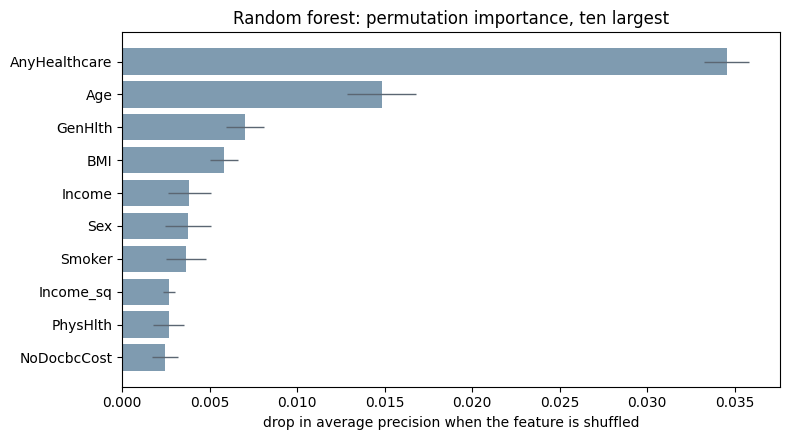

In [16]:
# ---- Plot the ten most important features ----
top = imp.head(10)[::-1]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top.index, top["drop in AP"], xerr=top["sd"],
        color="#7f9bb0", error_kw={"ecolor": "#5b6672", "lw": 1})
ax.set_xlabel("drop in average precision when the feature is shuffled")
ax.set_title(f"{best_name}: permutation importance, ten largest")
plt.tight_layout(); plt.show()

**One feature carries most of the signal.** Shuffling `AnyHealthcare` costs about 0.035 of
average precision, more than twice the next feature and roughly a third of the model's total
AP of 0.111. Whether someone has any health coverage is the single strongest indicator of
whether they have gone five years without a cholesterol check, which is what you would expect
and is reassuring rather than surprising.

**Age is second, then general health and BMI.** Age drops AP by about 0.015, general health by
0.007 and BMI by 0.006. After that the contributions fall below 0.004 and the error bars start
to overlap each other, so the ordering past the top four should not be read closely.

**Every feature has positive importance.** None of the eighteen features hurts the model when
shuffled, so there is nothing clearly worth dropping. That is a mild point in favour of the
feature set the team settled on in Task 2.

**The practical reading.** Coverage and cost questions do most of the work here, and the two
that matter most, `AnyHealthcare` and `NoDocbcCost`, are exactly the variables Task 1 withholds
because they measure access rather than disease. That split is the reason the two tasks need
separate feature sets, and this chart is the evidence for it.

## 4. Deployment

**How the model would be used.** A public health department runs outreach campaigns to get
people screened. It cannot contact everyone, so it needs a way to rank who to contact first.
This model scores each person on how likely they are to have gone five years without a
cholesterol check, and the department works down the list until the budget runs out.

**What it is worth.** Contacting people at random takes about 23 contacts to reach one person
who is overdue for screening. Working down the model's ranking takes about 12. For a fixed
outreach budget that is roughly twice as many people reached, and the gain comes from
reordering a list rather than from any new data collection.

**How it would be deployed.** The model is small and the inputs are plain survey answers, so
it does not need live serving. The practical form is a batch job: score a list, hand the
ranked output to whoever runs the campaign, and repeat when a new list arrives. Pairing it
with the Task 1 risk model gives the more useful target, people who look high risk *and*
have not been screened, which neither model identifies alone.

**What data it needs.** The eighteen features are all standard BRFSS items: demographics,
general health, a few habits, and two coverage and cost questions. Any intake form or
existing survey that asks the same questions can be scored. Nothing here requires a medical
record or a lab result, which is what makes the model usable before anyone has seen a doctor.

**How often it should be updated.** Retrain each time a new BRFSS year is released, which is
annual. Two things should be watched between retrains: the share of people flagged, which
drifts if screening rates move, and the precision actually observed in a campaign, which is
the only way to find out whether the model still holds up outside the test set. A sustained
drop in either is the signal to refit rather than wait for the next release.

**What it does not do.** The model predicts a gap in screening, not a diagnosis and not a
health outcome. It should prioritize outreach, not decide who receives care, and it should
not be used to infer anything about an individual beyond their place in a contact queue.